# SSFB Evaluation Analysis

Semantic State Feedback evaluation of an LLM against the APOLLO-SV ontology. This notebook runs an experiment end-to-end: loads the ontology, runs N trajectory runs against a local Ollama model, scores all responses, and visualizes the results.

## Configuration

In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

from apollo_eval.ontology_loader import OntologyLoader
from apollo_eval.vocab import OntologyVocabularyBuilder
from apollo_eval.question import Question
from apollo_eval.question_loader import build_question_bank
from apollo_eval.model_client import OllamaClient
from apollo_eval.policy import PolicyEngine
from apollo_eval.evaluation import EvaluationLayer

# --- Experiment parameters (edit these) ---
N_RUNS = 5
BASE_SEED = 42
OUTPUT_DIR = "trajectories"
SCENARIO_IRI = "http://example.org/scenario/measles_epidemic/"
SIMILARITY_THRESHOLD = 1.0   # 1.0 = exact only, 0.65 = fuzzy
MODEL = "llama3.2:1b"        # Ollama model name (e.g. "qwen2.5:7b", "llama3.2:3b")

# --- Set this to load a previous experiment instead of running a new one ---
# Example: LOAD_EXPERIMENT = "trajectories/notebook_run"
LOAD_EXPERIMENT = "trajectories/notebook_run"        # None = run new experiment

# --- Plot style ---
sns.set_theme(style="whitegrid", font_scale=1.1)
TYPE_COLORS = {"CM": "#4C72B0", "PR": "#DD8452", "DJ": "#55A868"}
TYPE_LABELS = {"CM": "Class Membership", "PR": "Property Restriction", "DJ": "Disjointness"}

## Load Ontology and Build Questions

In [2]:
loader = OntologyLoader()
graph = loader.load_graph()
graph = loader.apply_reasoning(graph)
ontology = OntologyVocabularyBuilder(graph).build(
    similarity_threshold=SIMILARITY_THRESHOLD,
)
Question.ontology = ontology
questions = build_question_bank(ontology)
print(f"{len(questions)} questions ready.")

25 questions ready.


## Run Experiment

Set `LOAD_EXPERIMENT` in the configuration cell to a path (e.g. `"trajectories/notebook_run"`) to skip this step and load previous results instead.

In [3]:
from datetime import datetime

if LOAD_EXPERIMENT:
    experiment_dir = LOAD_EXPERIMENT
    n_files = len([f for f in os.listdir(experiment_dir) if f.endswith(".json")])
    print(f"Loading existing experiment from: {experiment_dir} ({n_files} runs)")
else:
    experiment_id = datetime.now().strftime("%Y%m%d_%H%M%S")
    experiment_dir = os.path.join(OUTPUT_DIR, experiment_id)
    os.makedirs(experiment_dir, exist_ok=True)
    print(f"Experiment directory: {experiment_dir}")

    for i in range(N_RUNS):
        client = OllamaClient(model=MODEL)
        engine = PolicyEngine(
            questions=questions,
            client=client,
            seed=BASE_SEED + i,
            scenario_iri=SCENARIO_IRI,
        )
        engine.run()
        engine.save(experiment_dir)
        print(f"Run {i + 1}/{N_RUNS}: {engine.run_id}")

    print("Done.")

Loading existing experiment from: trajectories/notebook_run (5 runs)


## Process Results

Re-score all trajectories and build the evaluation DataFrame.

In [4]:
evaluator = EvaluationLayer(experiment_dir, questions)
df = evaluator.build_dataframe()

q_summary = evaluator.summary_by_question(df)
qt_summary = evaluator.summary_by_question_type(df)
pos_summary = evaluator.summary_by_position(df)
run_summary = evaluator.summary_by_run(df)
exp = evaluator.experiment_summary(df)

print(f"Experiment: {experiment_dir}")
print(f"Total turns: {exp['total_turns']}")
print(f"Runs: {exp['n_runs']}  |  Questions: {exp['n_questions']}")
print(f"Parse rate: {exp['parse_rate']:.1%}")
print(f"Overall consistency: {exp['consistency_rate']:.1%}")
for qt in ("CM", "PR", "DJ"):
    cr = exp[f"{qt}_consistency_rate"]
    pfr = exp[f"{qt}_parse_failure_rate"]
    cr_str = f"{cr:.1%}" if cr == cr else "N/A"
    print(f"  {qt}: consistency={cr_str}  parse_failure={pfr:.1%}")

Experiment: trajectories/notebook_run
Total turns: 125
Runs: 5  |  Questions: 25
Parse rate: 90.4%
Overall consistency: 69.9%
  CM: consistency=78.6%  parse_failure=6.7%
  PR: consistency=78.8%  parse_failure=17.5%
  DJ: consistency=37.5%  parse_failure=4.0%


## Consistency Rate by Question

Each bar is one question, colored by type (CM = Class Membership, PR = Property Restriction, DJ = Disjointness).

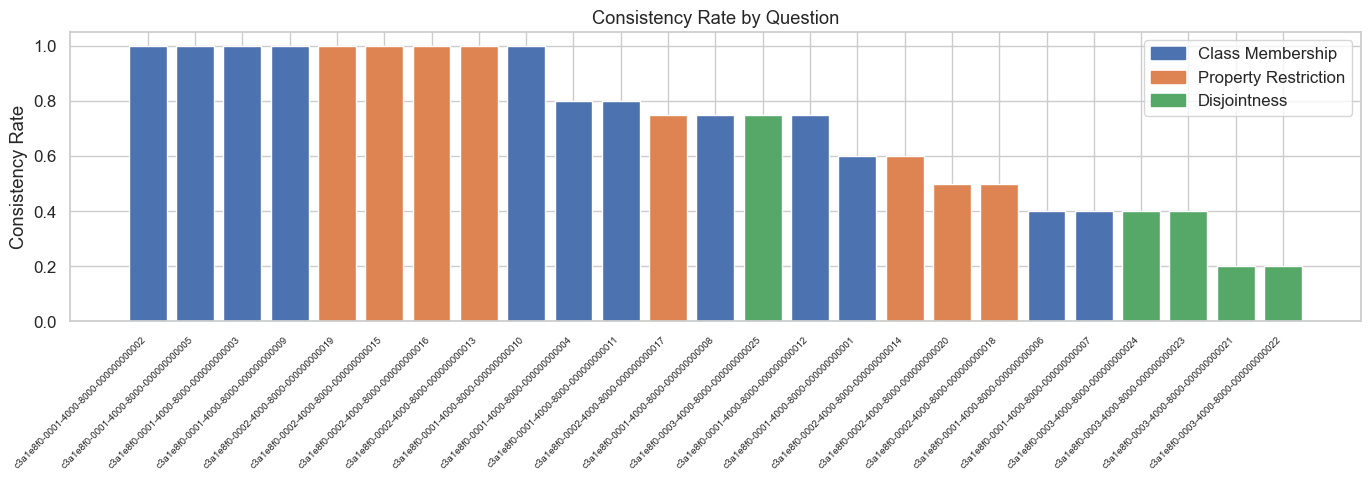

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
q_sorted = q_summary.sort_values("consistency_rate", ascending=False)
colors = [TYPE_COLORS[t] for t in q_sorted["question_type"]]
bars = ax.bar(range(len(q_sorted)), q_sorted["consistency_rate"], color=colors)
ax.set_xticks(range(len(q_sorted)))
ax.set_xticklabels(q_sorted.index, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("Consistency Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Consistency Rate by Question")
ax.legend(handles=[Patch(color=c, label=TYPE_LABELS[k]) for k, c in TYPE_COLORS.items()])
plt.tight_layout()
plt.show()

## Consistency Rate by Question Type

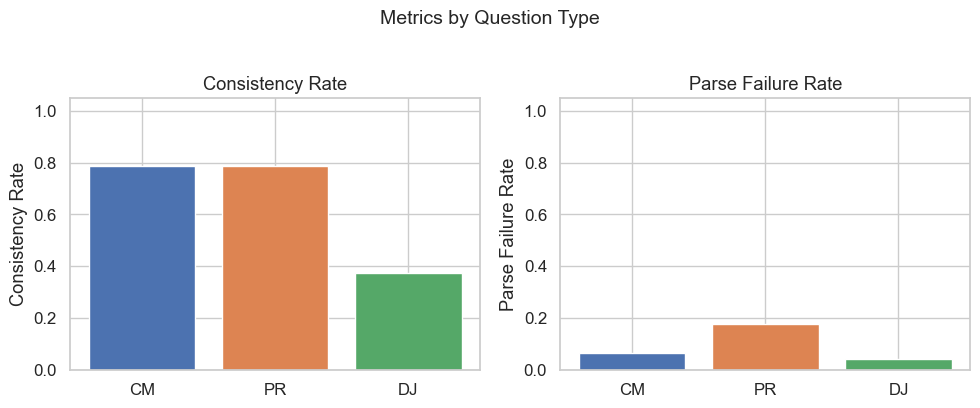

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Consistency rate
ax = axes[0]
qt_order = ["CM", "PR", "DJ"]
qt_plot = qt_summary.loc[qt_order]
ax.bar(qt_order, qt_plot["consistency_rate"], color=[TYPE_COLORS[t] for t in qt_order])
ax.set_ylabel("Consistency Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Consistency Rate")

# Parse failure rate
ax = axes[1]
ax.bar(qt_order, qt_plot["parse_failure_rate"], color=[TYPE_COLORS[t] for t in qt_order])
ax.set_ylabel("Parse Failure Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Parse Failure Rate")

plt.suptitle("Metrics by Question Type", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Position Effect

Does consistency degrade as the conversation progresses? Each point is the mean consistency rate across all runs at that turn position.

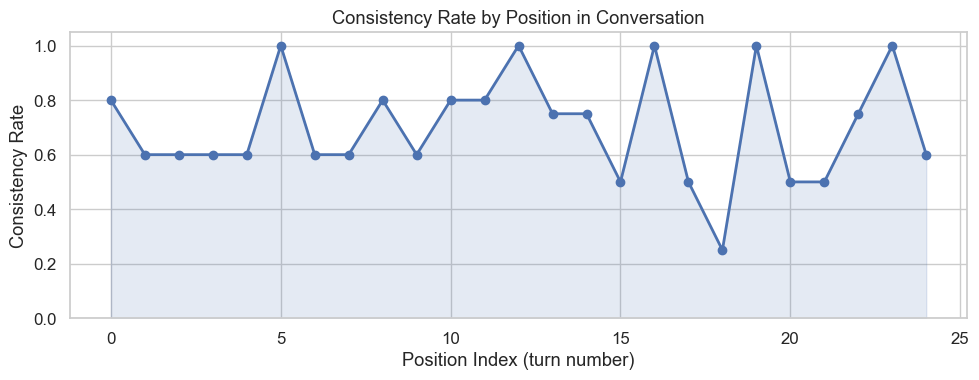

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pos_summary.index, pos_summary["consistency_rate"], marker="o", linewidth=2, color="#4C72B0")
ax.fill_between(pos_summary.index, pos_summary["consistency_rate"], alpha=0.15, color="#4C72B0")
ax.set_xlabel("Position Index (turn number)")
ax.set_ylabel("Consistency Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Consistency Rate by Position in Conversation")
plt.tight_layout()
plt.show()

## Trajectory Heatmap

Each row is one run, each column is a turn position. Green = consistent (1.0), red = inconsistent (0.0), black = parse failure.

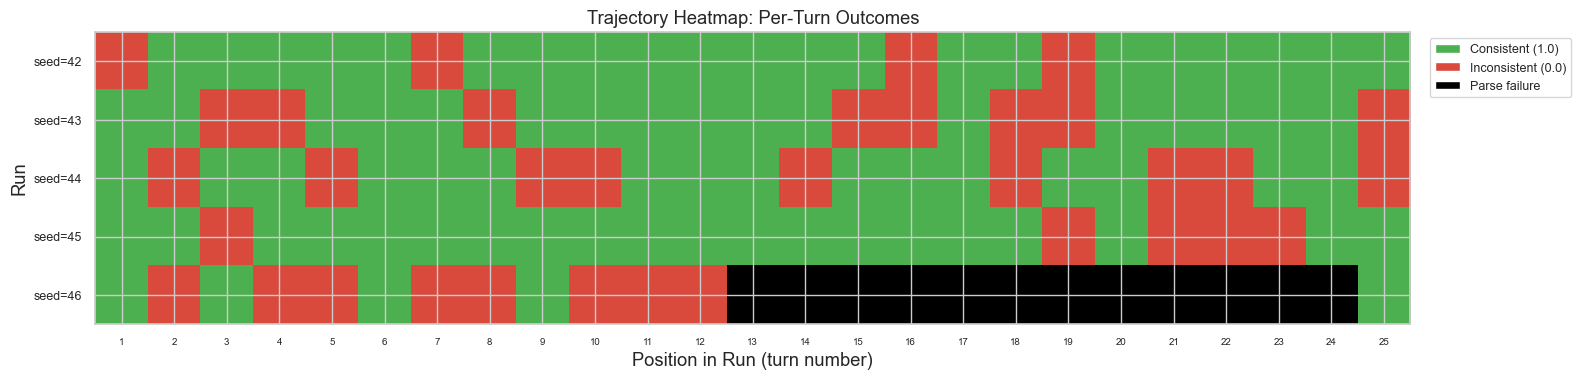

In [14]:
from matplotlib.colors import ListedColormap
import numpy as np

# Build a pivot: rows=runs (ordered by seed), columns=position_index
# Values: 1.0=pass, 0.0=fail, -1.0=parse failure (for coloring)
run_order = df.groupby("run_id")["seed"].first().sort_values()
ordered_run_ids = run_order.index.tolist()

grid = np.full((len(ordered_run_ids), 25), np.nan)
for row_idx, run_id in enumerate(ordered_run_ids):
    run_df = df[df["run_id"] == run_id].sort_values("position_index")
    for _, turn in run_df.iterrows():
        col = int(turn["position_index"])
        if not turn["parse_success"]:
            grid[row_idx, col] = -1.0  # parse failure
        else:
            grid[row_idx, col] = turn["score"]  # 1.0 or 0.0

# Colormap: -1=black (parse fail), 0=red (inconsistent), 1=green (consistent)
cmap = ListedColormap(["black", "#D94A3D", "#4CAF50"])
bounds = [-1.5, -0.5, 0.5, 1.5]
norm = plt.matplotlib.colors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(16, max(2, len(ordered_run_ids) * 0.6 + 1)))
im = ax.imshow(grid, cmap=cmap, norm=norm, aspect="auto", interpolation="nearest")

ax.set_xlabel("Position in Run (turn number)")
ax.set_ylabel("Run")
ax.set_xticks(range(25))
ax.set_xticklabels(range(1, 26), fontsize=7)
ax.set_yticks(range(len(ordered_run_ids)))
ax.set_yticklabels([f"seed={int(s)}" for s in run_order.values], fontsize=9)
ax.set_title("Trajectory Heatmap: Per-Turn Outcomes")

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4CAF50", label="Consistent (1.0)"),
    Patch(facecolor="#D94A3D", label="Inconsistent (0.0)"),
    Patch(facecolor="black", label="Parse failure"),
]
ax.legend(handles=legend_elements, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

### Observation: Conversation-Induced Refusal

The heatmap reveals a striking pattern in seed=46: after turn 12, the model begins returning "I can't help with that" for every remaining question. The other four runs (seeds 42–45) complete all 25 turns without any parse failures.

This is not a framework bug — each run starts with a fresh client and empty conversation history. The refusal is **within-run** behavior: as the PolicyEngine accumulates (question, response) pairs in the conversation history, the growing context eventually triggers `llama3.2:1b`'s safety guardrails, causing it to refuse all subsequent prompts.

Key points:
- The effect is **question-order-dependent**: seed=46 produces a particular random shuffle that triggers refusal around turn 12, while other seeds do not
- The model is not degrading in quality — it is actively refusing to engage, producing responses with no ontology terms and therefore no parseable content
- This is exactly the kind of state-dependent behavior the SSFB framework is designed to detect: the model's hidden state (accumulated context) changes its output distribution in a way that is inconsistent with the ontology-grounded evaluation

## Parse Failure Rate by Question

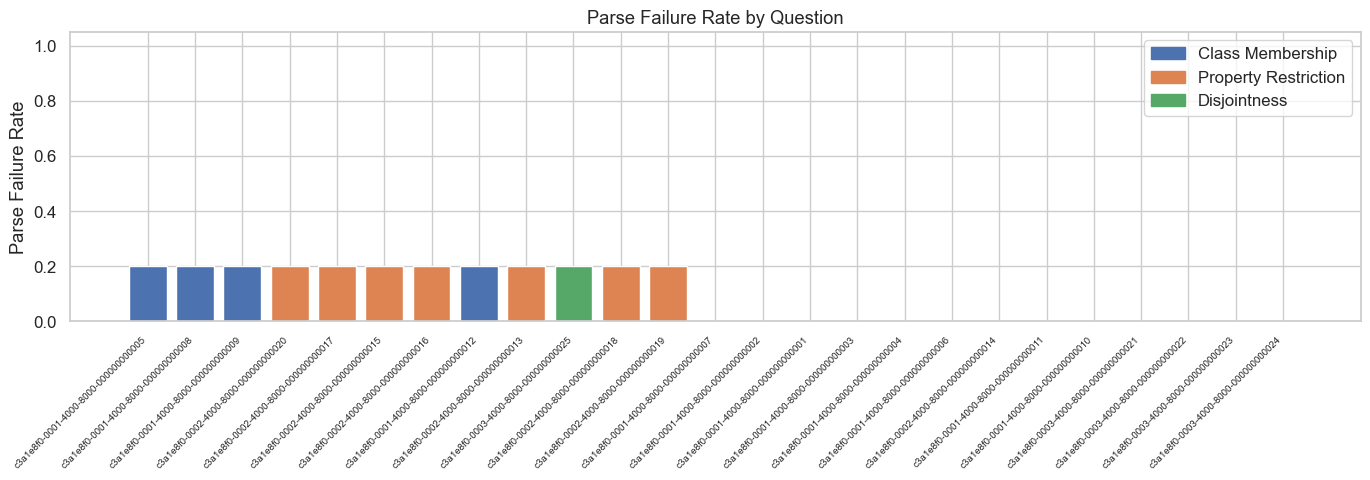

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
q_sorted = q_summary.sort_values("parse_failure_rate", ascending=False)
colors = [TYPE_COLORS[t] for t in q_sorted["question_type"]]
ax.bar(range(len(q_sorted)), q_sorted["parse_failure_rate"], color=colors)
ax.set_xticks(range(len(q_sorted)))
ax.set_xticklabels(q_sorted.index, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("Parse Failure Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Parse Failure Rate by Question")
ax.legend(handles=[Patch(color=c, label=TYPE_LABELS[k]) for k, c in TYPE_COLORS.items()])
plt.tight_layout()
plt.show()

## Similarity Fallback Rate

Only meaningful when `SIMILARITY_THRESHOLD < 1.0`. Shows how often the fuzzy matching fallback was used.

In [9]:
if SIMILARITY_THRESHOLD < 1.0:
    fig, ax = plt.subplots(figsize=(14, 5))
    q_sorted = q_summary.sort_values("fuzz_rate", ascending=False)
    colors = [TYPE_COLORS[t] for t in q_sorted["question_type"]]
    ax.bar(range(len(q_sorted)), q_sorted["fuzz_rate"].fillna(0), color=colors)
    ax.set_xticks(range(len(q_sorted)))
    ax.set_xticklabels(q_sorted.index, rotation=45, ha="right", fontsize=7)
    ax.set_ylabel("Fuzz Rate (similarity fallback)")
    ax.set_ylim(0, 1.05)
    ax.set_title("Similarity Fallback Rate by Question")
    ax.legend(handles=[Patch(color=c, label=TYPE_LABELS[k]) for k, c in TYPE_COLORS.items()])
    plt.tight_layout()
    plt.show()
else:
    print("Similarity matching disabled (threshold=1.0). Skipping fuzz rate chart.")

Similarity matching disabled (threshold=1.0). Skipping fuzz rate chart.


## Per-Run Consistency

Variance across independent seeds. The red dashed line is the overall mean.

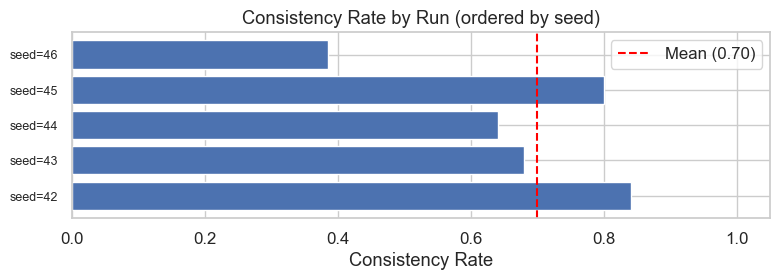

In [10]:
# Build run summary with seed for ordering
run_seed = df.groupby("run_id")["seed"].first()
run_summary_ordered = run_summary.copy()
run_summary_ordered["seed"] = run_seed
run_summary_ordered = run_summary_ordered.sort_values("seed")

fig, ax = plt.subplots(figsize=(8, max(3, len(run_summary_ordered) * 0.5)))
y_labels = [f"seed={int(s)}" for s in run_summary_ordered["seed"]]
bars = ax.barh(range(len(run_summary_ordered)), run_summary_ordered["consistency_rate"], color="#4C72B0")
ax.set_yticks(range(len(run_summary_ordered)))
ax.set_yticklabels(y_labels, fontsize=9)
ax.set_xlabel("Consistency Rate")
ax.set_xlim(0, 1.05)
ax.set_title("Consistency Rate by Run (ordered by seed)")
ax.axvline(exp["consistency_rate"], color="red", linestyle="--", linewidth=1.5,
           label=f"Mean ({exp['consistency_rate']:.2f})")
ax.legend()
plt.tight_layout()
plt.show()

## Experiment Summary

In [11]:
def fmt_pct(v):
    return f"{v:.1%}" if v == v else "N/A"

summary_rows = [
    ("Total Turns", str(exp["total_turns"])),
    ("Runs", str(exp["n_runs"])),
    ("Questions", str(exp["n_questions"])),
    ("Parse Rate", fmt_pct(exp["parse_rate"])),
    ("Overall Consistency", fmt_pct(exp["consistency_rate"])),
    ("", ""),
    ("CM Consistency", fmt_pct(exp["CM_consistency_rate"])),
    ("CM Parse Failure", fmt_pct(exp["CM_parse_failure_rate"])),
    ("PR Consistency", fmt_pct(exp["PR_consistency_rate"])),
    ("PR Parse Failure", fmt_pct(exp["PR_parse_failure_rate"])),
    ("DJ Consistency", fmt_pct(exp["DJ_consistency_rate"])),
    ("DJ Parse Failure", fmt_pct(exp["DJ_parse_failure_rate"])),
]

summary_df = pd.DataFrame(summary_rows, columns=["Metric", "Value"])
summary_df = summary_df[summary_df["Metric"] != ""]
summary_df.style.hide(axis="index")

Metric,Value
Total Turns,125
Runs,5
Questions,25
Parse Rate,90.4%
Overall Consistency,69.9%
CM Consistency,78.6%
CM Parse Failure,6.7%
PR Consistency,78.8%
PR Parse Failure,17.5%
DJ Consistency,37.5%
